# Passaggio 2 (versione 2): dati di prezzo intraday delle coppie della versione 2

**Obiettivo.** Dal dataset a 1 minuto (`data/processed/intraday_1m_all.parquet`) costruire, per ognuna delle **15 coppie della versione 2** (`selected_pairs_2.csv`, vedi [01_coppie.ipynb](01_coppie.ipynb)), un **file pulito** con i due titoli allineati sugli stessi minuti. Sarà il punto di partenza per il segnale (Passaggio 4) e per la simulazione (Passaggio 6).

**Versione 1 e versione 2.** La versione 1 sono le prime 10 coppie ([intraday_pulizia.ipynb](../Old%20files/src/02_dati_intraday/intraday_pulizia.ipynb), ora in `Old files/`; file in `data/processed/pairs_intraday/`). Questo notebook fa **lo stesso identico lavoro** sulle coppie della versione 2 e scrive in una cartella **separata**, `data/processed/pairs_intraday_v2/`, così le due versioni non si mescolano e non si sovrascrivono. Il metodo di pulizia è lo stesso della versione 1: cambia solo la lista delle coppie e quindi i titoli.

**Cosa fa il notebook**

| Parte | Cosa fa | Perché |
|---|---|---|
| 1-2 | Parametri e caricamento dei 30 titoli | si lavora solo sui titoli che servono |
| 3 | Controllo dei prezzi non aggiustati | gli split non devono sembrare crolli |
| 4 | Qualità dei dati grezzi | barre per giorno, giorni mancanti, giorni a orario ridotto |
| 5 | Funzione di pulizia: allineamento e riempimento | il cuore del passaggio |
| 6 | Pulizia delle 15 coppie e controlli | quante barre riempite o scartate |
| 7 | Barre da 5, 15 e 60 minuti | per scegliere la frequenza dopo (decisione 1 del programma) |
| 8 | Un grafico per coppia | controllo a occhio |
| 9 | Risultati (testo per il report) | numeri generati dai dati |
| 10 | Salvataggio e riepilogo | file per le fasi successive |

**Regole del programma applicate** (Passaggio 2 di `docs/Programma.md`):
- un solo fuso orario, l'ora di New York (i dati sono già convertiti da `src/data.py`), e solo la **seduta regolare, 09:30-15:59** (390 barre da 1 minuto);
- i due titoli di ogni coppia sono **allineati sullo stesso orario**;
- le barre mancanti si riempiono **solo copiando in avanti il prezzo precedente, mai con prezzi futuri** (Lezione 5): usare prezzi futuri sarebbe lookahead bias;
- i prezzi dovrebbero essere **aggiustati per split e dividendi**: l'intraday non lo è, quindi si controlla l'assenza di split (parte 3);
- controlli: numero di barre per giorno, giorni a orario ridotto, un grafico per coppia.

**Cosa NON si tocca:** la lista delle coppie della versione 2, i dati del periodo di selezione giornaliero e le soglie del Passaggio 1. Nessuna coppia viene scartata in questo passaggio.

## 1. Parametri

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, next(str(p) for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()))   # cartella del progetto: rende importabile src

import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt

from src.config import PAIRS_DIR, PROCESSED, SELECTED

INTRADAY = PROCESSED / "intraday_1m_all.parquet"    # barre da 1 minuto, orari di New York
DAILY    = PROCESSED / "daily_all.parquet"
OUT_DIR  = PAIRS_DIR                                # file puliti, uno per coppia e per frequenza

SESSION_OPEN_MIN = 9 * 60 + 30      # apertura 09:30, in minuti dalla mezzanotte
N_MINUTES = 390                     # barre da 1 minuto nella seduta regolare: 09:30-15:59
FREQUENCIES = [1, 5, 15, 60]        # minuti per barra
# [ECO] Il programma dice di tenere il minuto e creare le altre con resample: la frequenza giusta si sceglie
#   confrontando i risultati (decisione 1), quindi si salvano tutte.

SPLIT_GAP = 0.15                    # gap tra chiusura di ieri e apertura di oggi oltre il 15%: sospetto split
CLOSE_VS_DAILY_TOL = 0.05           # chiusura intraday contro PX_LAST giornaliero oltre il 5%: sospetto prezzo non aggiustato
JUMP_1MIN = 0.05                    # rendimento a 1 minuto oltre il 5%: da controllare
HALF_DAY_LAST_BAR = "15:30"         # se la mediana dell'ultima barra dei titoli e prima, e un giorno a orario ridotto
# [NOSTRA] Soglie di allarme per i controlli: non scartano dati da sole, servono a far emergere i casi da guardare a mano.

## 2. Caricamento dei 30 titoli delle coppie

Si leggono solo i titoli delle coppie (30 su 503): il dataset intero ha oltre 13 milioni di righe. DuckDB legge il file senza caricarlo tutto in memoria. L'orario è l'ora di New York **senza indicazione del fuso** nel dato (tutti i minuti sono già in ora di New York, quindi il confronto tra giorni resta corretto anche col cambio dell'ora legale, che nel periodo giugno-ottobre cade solo a novembre).

In [2]:
pairs = pd.read_csv(SELECTED)
pairs["origine"] = "versione 2"    # tutte scelte dalla regola, nessuna aggiunta a mano
tickers = sorted(set(pairs["A"]) | set(pairs["B"]))
in_list = ", ".join(repr(t) for t in tickers)

raw = duckdb.sql(f'''
    SELECT ticker, date, time, open, high, low, close, volume, n_events
    FROM '{INTRADAY.as_posix()}' WHERE ticker IN ({in_list})
''').df()
raw["ts"] = pd.to_datetime(raw["date"].astype(str) + " " + raw["time"].astype(str))
raw["date"] = pd.to_datetime(raw["date"])
raw = raw.drop(columns="time").sort_values(["ticker", "ts"]).reset_index(drop=True)

print(f"{len(tickers)} titoli, {len(raw):,} barre da 1 minuto, dal {raw['date'].min().date()} al {raw['date'].max().date()}")
print("barre fuori da 09:30-15:59:", int(((raw['ts'].dt.hour * 60 + raw['ts'].dt.minute < SESSION_OPEN_MIN) | (raw['ts'].dt.hour * 60 + raw['ts'].dt.minute >= SESSION_OPEN_MIN + N_MINUTES)).sum()))

30 titoli, 979,861 barre da 1 minuto, dal 2026-06-16 al 2026-10-30
barre fuori da 09:30-15:59: 0


## 3. Controllo: i prezzi intraday non sono aggiustati

I prezzi giornalieri (`PX_LAST`) sono aggiustati per split e dividendi, quelli intraday **no**: uno split (per esempio 2 azioni per 1) compare come un gap del -50% da una sera alla mattina dopo, e farebbe sembrare enorme uno spread che non lo è. Due controlli:
1. **Gap tra la chiusura di un giorno e l'apertura del giorno dopo**, per ogni titolo: oltre il 15% è sospetto.
2. **Ultima barra del giorno contro il `PX_LAST` giornaliero** dello stesso giorno: se i due prezzi differiscono di più del 5%, uno dei due non è confrontabile (tipico di uno split avvenuto dopo, che il giornaliero ha già corretto sulla storia).

Se uno split compare, i prezzi precedenti allo split vanno divisi per il suo fattore, e la correzione va dichiarata.

In [3]:
sess = raw.groupby(["ticker", "date"]).agg(first_open=("open", "first"), last_close=("close", "last"), bars=("close", "size"),
                                           first_bar=("ts", "min"), last_bar=("ts", "max")).reset_index()
sess["gap"] = sess["first_open"] / sess.groupby("ticker")["last_close"].shift() - 1

daily = duckdb.sql(f"SELECT ticker, CAST(date AS TIMESTAMP) AS date, PX_LAST FROM '{DAILY.as_posix()}' WHERE ticker IN ({in_list}) AND date >= '{raw['date'].min().date()}'").df()
sess = sess.merge(daily, on=["ticker", "date"], how="left")
sess["close_vs_daily"] = sess["last_close"] / sess["PX_LAST"] - 1

suspect_gap = sess[sess["gap"].abs() > SPLIT_GAP]
suspect_px = sess[sess["close_vs_daily"].abs() > CLOSE_VS_DAILY_TOL]
print(f"gap overnight oltre {SPLIT_GAP:.0%}: {len(suspect_gap)} casi | chiusura intraday oltre {CLOSE_VS_DAILY_TOL:.0%} dal giornaliero: {len(suspect_px)} casi")
display(sess.groupby("ticker")[["gap", "close_vs_daily"]].agg(lambda s: s.abs().max()).rename(columns={"gap": "gap_max", "close_vs_daily": "diff_max_dal_giornaliero"}).round(4))
suspect_gap[["ticker", "date", "first_open", "last_close", "gap", "PX_LAST"]].assign(gap=lambda d: d["gap"].round(4))

gap overnight oltre 15%: 2 casi | chiusura intraday oltre 5% dal giornaliero: 0 casi


,gap_max,diff_max_dal_giornaliero
ticker,,
BAC UN Equity,0.0805,0.0061
C UN Equity,0.0263,0.0115
CL UN Equity,0.0515,0.0119
COP UN Equity,0.0431,0.0070
CRM UN Equity,0.1340,0.0040
CSX UW Equity,0.0425,0.0027
DHR UN Equity,0.1655,0.0045
ELV UN Equity,0.0821,0.0127
EOG UN Equity,0.0379,0.0147


,ticker,date,first_open,last_close,gap,PX_LAST
589,DHR UN Equity,2026-07-21,168.25,179.01,-0.1655,178.6933
1919,PYPL UW Equity,2026-07-15,54.87,55.52,0.1583,55.3832


**Lettura.** Una chiusura intraday sempre entro il 5% dal giornaliero esclude uno split nel periodo (la tabella sopra riporta la differenza massima per titolo): dopo uno split i due prezzi differirebbero di un fattore intero. Un gap overnight grande **non** è per forza uno split: può essere una notizia vera. Per distinguere si guarda se il giornaliero (aggiustato) mostra lo stesso movimento: se sì, è un movimento reale e i prezzi intraday sono utilizzabili così come sono.

## 4. Qualità dei dati grezzi

Tre cose da conoscere prima di pulire:
- **Giorni mancanti.** Un titolo può non avere dati in alcuni giorni (il controllo sul dataset intero aveva già segnalato giorni di settembre).
- **Barre mancanti.** Nel dato grezzo c'è una barra solo nei minuti in cui è avvenuto almeno uno scambio: i titoli meno scambiati hanno molti minuti vuoti. Un minuto vuoto non è un dato errato: vuol dire che il prezzo non è cambiato (nessuno scambio).
- **Giorni a orario ridotto.** Nei giorni a seduta ridotta (per esempio alla vigilia di alcune festività) la borsa chiude prima: le barre dopo la chiusura non esistono e non vanno "inventate".

In [4]:
day_bars = sess.pivot(index="date", columns="ticker", values="bars")
print("giorni di borsa nel periodo (almeno un titolo):", len(day_bars))
missing = day_bars.isna().sum()
display(pd.DataFrame({"giorni_presenti": day_bars.notna().sum(), "giorni_mancanti": missing,
                      "barre_per_giorno_mediana": day_bars.median().round(0), "barre_per_giorno_min": day_bars.min()}))
for tk in missing[missing > 0].index:
    print(tk, "manca nei giorni:", ", ".join(d.strftime("%Y-%m-%d") for d in day_bars.index[day_bars[tk].isna()]))

giorni di borsa nel periodo (almeno un titolo): 96


,giorni_presenti,giorni_mancanti,barre_per_giorno_mediana,barre_per_giorno_min
ticker,,,,
BAC UN Equity,96,0,389.0,376.0
C UN Equity,96,0,372.0,293.0
CL UN Equity,96,0,339.0,261.0
COP UN Equity,91,5,386.0,324.0
CRM UN Equity,96,0,378.0,318.0
CSX UW Equity,91,5,383.0,351.0
DHR UN Equity,96,0,289.0,208.0
ELV UN Equity,96,0,245.0,160.0
EOG UN Equity,96,0,306.0,222.0


COP UN Equity manca nei giorni: 2026-09-11, 2026-09-14, 2026-09-15, 2026-09-16, 2026-09-17
CSX UW Equity manca nei giorni: 2026-09-11, 2026-09-14, 2026-09-15, 2026-09-16, 2026-09-17
GS UN Equity manca nei giorni: 2026-09-11, 2026-09-14, 2026-09-15, 2026-09-16, 2026-09-17
LOW UN Equity manca nei giorni: 2026-09-11, 2026-09-14, 2026-09-15, 2026-09-16, 2026-09-17
SYK UN Equity manca nei giorni: 2026-09-11, 2026-09-14, 2026-09-15, 2026-09-16, 2026-09-17
TMO UN Equity manca nei giorni: 2026-09-11, 2026-09-14, 2026-09-15, 2026-09-16, 2026-09-17


In [5]:
# giorni a orario ridotto: ultima barra mediana dei titoli presente prima delle 15:30
last = sess.assign(last_min=sess["last_bar"].dt.hour * 60 + sess["last_bar"].dt.minute).groupby("date")["last_min"].median()
limit = int(HALF_DAY_LAST_BAR[:2]) * 60 + int(HALF_DAY_LAST_BAR[3:])
half_days = last[last < limit]
print("giorni a orario ridotto:", [d.strftime("%Y-%m-%d") for d in half_days.index] or "nessuno")
print("giorni con meno barre (mediana tra i titoli):")
day_bars.median(axis=1).sort_values().head(5).to_frame("barre_mediane")

giorni a orario ridotto: nessuno
giorni con meno barre (mediana tra i titoli):


,barre_mediane
date,
2026-07-10,330.5
2026-07-09,337.5
2026-08-26,339.5
2026-10-06,341.5
2026-10-09,342.0


## 5. Come si pulisce una coppia

Per ogni coppia (titolo A e titolo B) si fanno quattro passaggi, ognuno con il suo motivo.

1. **Giorni in comune.** Si tengono solo i giorni in cui **entrambi** i titoli hanno dati. Se uno dei due manca, l'altro non ha con chi formare lo spread, e inventare un giorno intero sarebbe sbagliato. I giorni scartati si contano e si riportano.
2. **Griglia completa di 390 minuti** (09:30-15:59) per ogni giorno tenuto: ogni titolo viene portato sulla stessa griglia, così le due serie si confrontano riga per riga.
3. **Riempimento in avanti, solo dentro la stessa giornata.** Un minuto senza scambi prende il prezzo di chiusura dell'ultima barra precedente **dello stesso giorno**: apertura, massimo, minimo e chiusura uguali a quel prezzo, volume 0. Non si copia mai il prezzo del giorno prima sul giorno dopo: tra le 16:00 e le 9:30 il prezzo può essere cambiato (notizie, utili), e un prezzo copiato attraverso la notte sarebbe falso. Il riempimento in avanti non usa mai informazione futura (nessun lookahead bias). Ogni barra riempita ha `filled = True`, così si può sempre contare e capire quanto del dato è "vero".
4. **Minuti iniziali senza prezzo.** Se un titolo fa il primo scambio dopo le 9:30, per i minuti precedenti non esiste un prezzo del giorno: **non si inventano**. Si scartano quei minuti per entrambi i titoli, fino al primo minuto in cui hanno tutti e due un prezzo. (Il programma prevede comunque di escludere i primi 30 minuti dalle operazioni, perché i prezzi sono instabili.)

**Formato del file** (un file per coppia, un titolo per riga, come nella tabella dei file scambiati del programma): `ts` (orario di New York), `ticker`, `open`, `high`, `low`, `close`, `volume`, `n_events`, `filled`.

In [6]:
grid_offsets = pd.to_timedelta(np.arange(N_MINUTES) + SESSION_OPEN_MIN, unit="min")    # 09:30 ... 15:59

def clean_pair(a, b):
    # Ritorna (dati puliti in formato lungo, statistiche) per la coppia a, b.
    by_ticker = {tk: raw[raw["ticker"] == tk] for tk in (a, b)}
    days_a, days_b = set(by_ticker[a]["date"]), set(by_ticker[b]["date"])
    days = sorted(days_a & days_b)
    dropped_days = sorted((days_a | days_b) - set(days))

    grid = pd.DatetimeIndex([d + off for d in days for off in grid_offsets])
    day_of = grid.normalize()
    parts = {}
    for tk in (a, b):
        s = by_ticker[tk][by_ticker[tk]["date"].isin(days)].set_index("ts")[["open", "high", "low", "close", "volume", "n_events"]].reindex(grid)
        filled = s["close"].isna()
        close = s["close"].groupby(day_of).ffill()           # solo dentro lo stesso giorno
        out = pd.DataFrame({"ts": grid, "ticker": tk, "open": s["open"], "high": s["high"], "low": s["low"], "close": close,
                            "volume": s["volume"].fillna(0).astype("int64"), "n_events": s["n_events"].fillna(0).astype("int64"), "filled": filled.values})
        for col in ("open", "high", "low"):
            out[col] = out[col].where(~filled, out["close"])    # barra riempita: open = high = low = close = ultimo prezzo noto
        parts[tk] = out.reset_index(drop=True)

    both = parts[a]["close"].notna().values & parts[b]["close"].notna().values       # niente prezzo inventato ai minuti iniziali
    long = pd.concat([parts[a][both], parts[b][both]]).sort_values(["ts", "ticker"]).reset_index(drop=True)

    stats = dict(pair=None, giorni_tenuti=len(days), giorni_scartati=len(dropped_days),
                 giorni_scartati_elenco=", ".join(d.strftime("%m-%d") for d in dropped_days) or "-",
                 minuti_iniziali_scartati=int((~both).sum()), barre_per_titolo=int(both.sum()),
                 titolo_A=a.split()[0], titolo_B=b.split()[0])
    for side, tk in (("A", a), ("B", b)):
        t = long[long["ticker"] == tk]
        stats[f"filled_%_{side}"] = round(100 * t["filled"].mean(), 1)
        ret = t.groupby(t["ts"].dt.normalize())["close"].pct_change()
        stats[f"salti_1min_{side}"] = int((ret.abs() > JUMP_1MIN).sum())
    return long, stats

## 6. Pulizia delle 15 coppie e controlli

Per ogni coppia la tabella mostra: quanti giorni restano e quali sono scartati, quanti minuti iniziali si perdono (in tutto il periodo), la quota di barre riempite per titolo (A e B, come nella lista delle coppie) e i salti di prezzo a 1 minuto oltre il 5% (da guardare a mano). Una quota alta di barre riempite non è un errore, ma segnala un titolo poco scambiato: il suo spread cambia meno spesso di quanto sembri.

In [7]:
clean, summary = {}, []
for _, row in pairs.iterrows():
    long, st = clean_pair(row["A"], row["B"])
    st["pair"] = row["pair"]; st["origine"] = row["origine"]
    clean[row["pair"]] = long
    summary.append(st)
quality = pd.DataFrame(summary).set_index("pair")

In [8]:
quality = quality[["origine", "titolo_A", "titolo_B", "giorni_tenuti", "giorni_scartati", "giorni_scartati_elenco", "minuti_iniziali_scartati",
                   "barre_per_titolo", "filled_%_A", "filled_%_B", "salti_1min_A", "salti_1min_B"]]
quality

,origine,titolo_A,titolo_B,giorni_tenuti,giorni_scartati,giorni_scartati_elenco,minuti_iniziali_scartati,barre_per_titolo,filled_%_A,filled_%_B,salti_1min_A,salti_1min_B
pair,,,,,,,,,,,,
MA-V,versione 2,MA,V,96,0,-,0,37440,9.4,1.3,0,0
CSX-UNP,versione 2,CSX,UNP,91,5,"09-11, 09-14, 09-15, 09-16, 09-17",0,35490,2.4,41.4,0,0
PYPL-XYZ,versione 2,PYPL,XYZ,96,0,-,74,37366,1.3,13.5,0,0
HD-LOW,versione 2,HD,LOW,91,5,"09-11, 09-14, 09-15, 09-16, 09-17",24,35466,5.2,31.9,0,0
DHR-TMO,versione 2,DHR,TMO,91,5,"09-11, 09-14, 09-15, 09-16, 09-17",11,35479,25.4,22.1,0,0
CRM-WDAY,versione 2,CRM,WDAY,96,0,-,3,37437,4.3,12.7,0,3
JPM-WFC,versione 2,JPM,WFC,96,0,-,109,37331,1.4,2.5,0,0
NXPI-TXN,versione 2,NXPI,TXN,96,0,-,0,37440,22.9,7.9,0,0
ELV-UNH,versione 2,ELV,UNH,96,0,-,1,37439,35.8,4.3,0,0


**Come leggere la tabella.** I giorni scartati sono quelli in cui uno dei due titoli non ha dati: le coppie che contengono quel titolo perdono quel giorno. Una quota di barre riempite alta (sopra il 40-50%) vuol dire che quel titolo ha molti minuti senza scambi: non è un errore, ma lo spread cambia meno spesso di quanto sembri (vedi la decisione B del Passaggio 2 nel Programma). Il testo con i numeri è generato nella parte 9.

## 7. Barre da 5, 15 e 60 minuti

Il programma dice di scaricare una sola volta il minuto e creare le altre frequenze con un ricampionamento (`resample`). Ogni barra aggrega i minuti che contiene: **apertura** = prima apertura, **massimo** = massimo dei massimi, **minimo** = minimo dei minimi, **chiusura** = ultima chiusura, **volume** = somma. Le barre iniziano alle 09:30 (per esempio da 60 minuti: 09:30, 10:30, … , 15:30; l'ultima dura 30 minuti, fino alle 15:59). In più, `filled_share` è la quota di minuti riempiti della barra (0 = tutti con scambi, 1 = barra interamente riempita).

In [9]:
def resample_bars(long, minutes):
    base = long.assign(filled_share=long["filled"].astype(float)).drop(columns=["filled", "n_events"])
    if minutes == 1:
        return base
    mins_from_open = (long["ts"] - long["ts"].dt.normalize()) / pd.Timedelta(minutes=1) - SESSION_OPEN_MIN
    start = long["ts"].dt.normalize() + pd.to_timedelta(SESSION_OPEN_MIN + (mins_from_open // minutes) * minutes, unit="min")
    g = base.groupby(["ticker", start.rename("ts")], sort=True)
    out = g.agg(open=("open", "first"), high=("high", "max"), low=("low", "min"), close=("close", "last"),
                volume=("volume", "sum"), filled_share=("filled_share", "mean")).reset_index()
    return out.sort_values(["ts", "ticker"]).reset_index(drop=True)

counts = pd.DataFrame({f"{m} min": {p: len(resample_bars(clean[p], m)) // 2 for p in clean} for m in FREQUENCIES})
print("barre per titolo, per coppia e frequenza (dopo la pulizia):")
counts

barre per titolo, per coppia e frequenza (dopo la pulizia):


,1 min,5 min,15 min,60 min
MA-V,37440,7488,2496,672
CSX-UNP,35490,7098,2366,637
PYPL-XYZ,37366,7488,2496,672
HD-LOW,35466,7098,2366,637
DHR-TMO,35479,7098,2366,637
CRM-WDAY,37437,7488,2496,672
JPM-WFC,37331,7483,2496,672
NXPI-TXN,37440,7488,2496,672
ELV-UNH,37439,7488,2496,672
CL-PG,37384,7488,2496,672


## 8. Un grafico per coppia

Controllo a occhio: in alto i due prezzi riportati a 1 all'inizio (si devono muovere insieme, senza salti improvvisi), in basso lo **spread** (logaritmo del rapporto tra i due prezzi, meno la sua media), su barre da 15 minuti. Un salto di prezzo isolato, o uno spread che sale in una sola direzione per tutto il periodo, sono segnali da guardare.

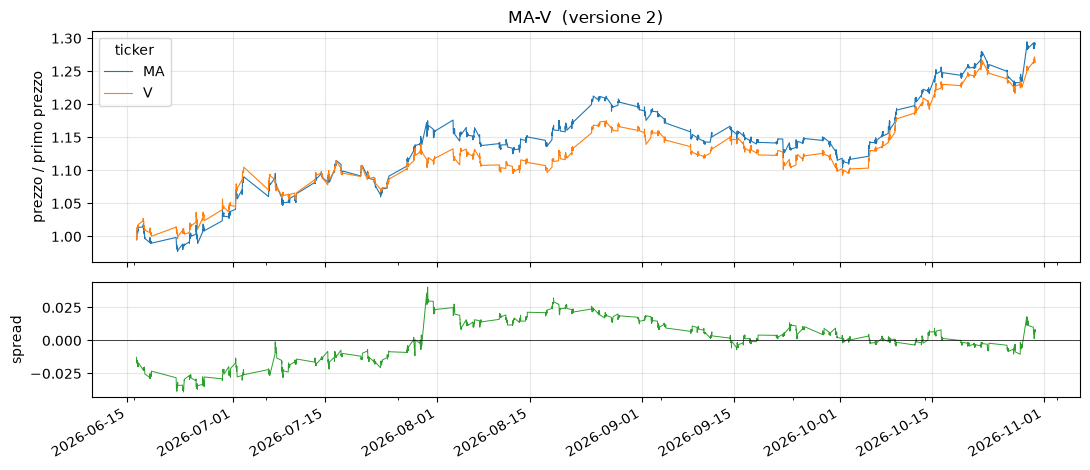

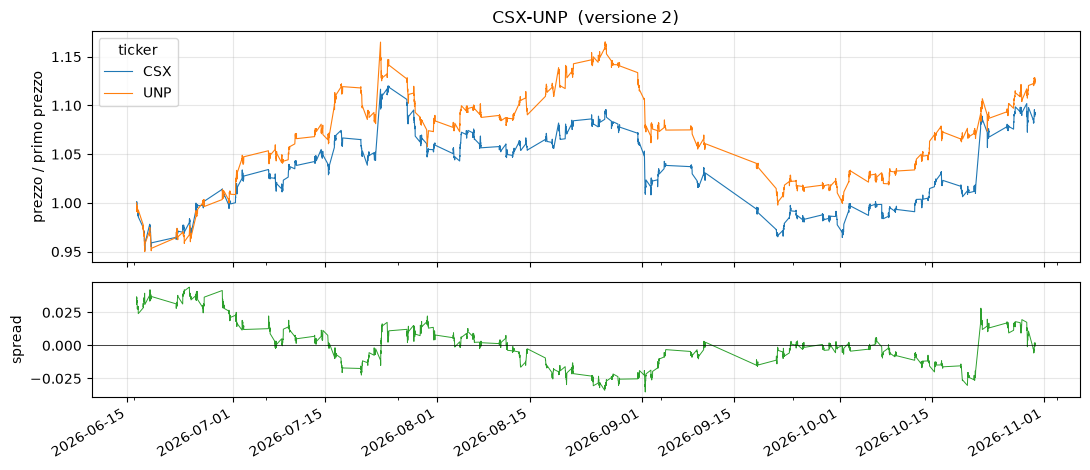

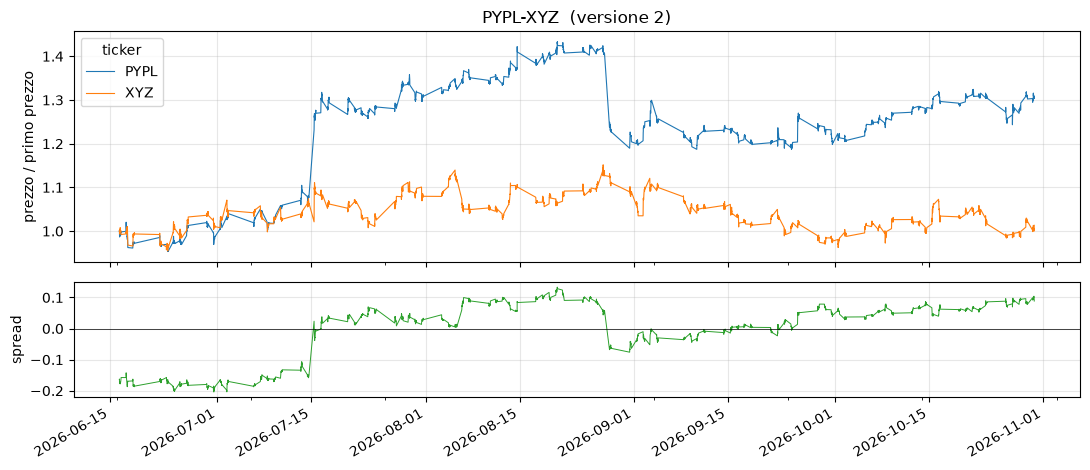

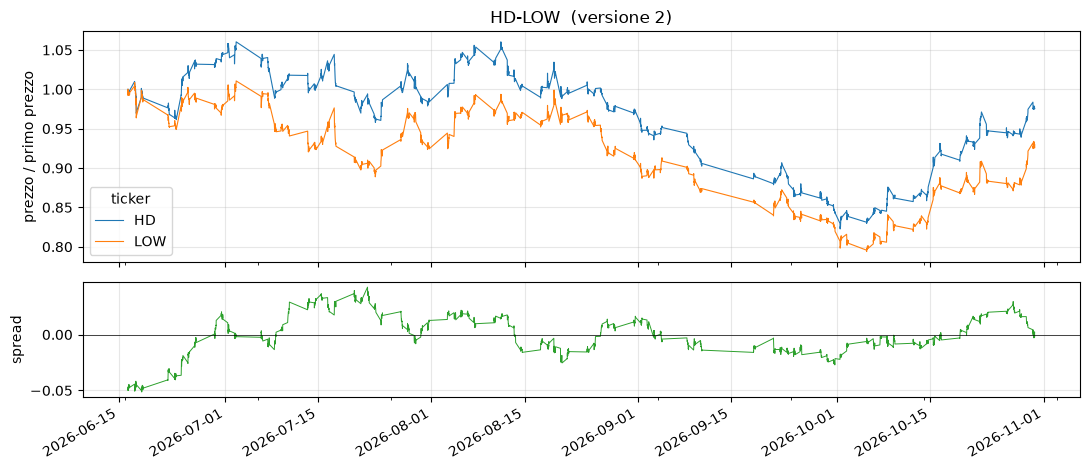

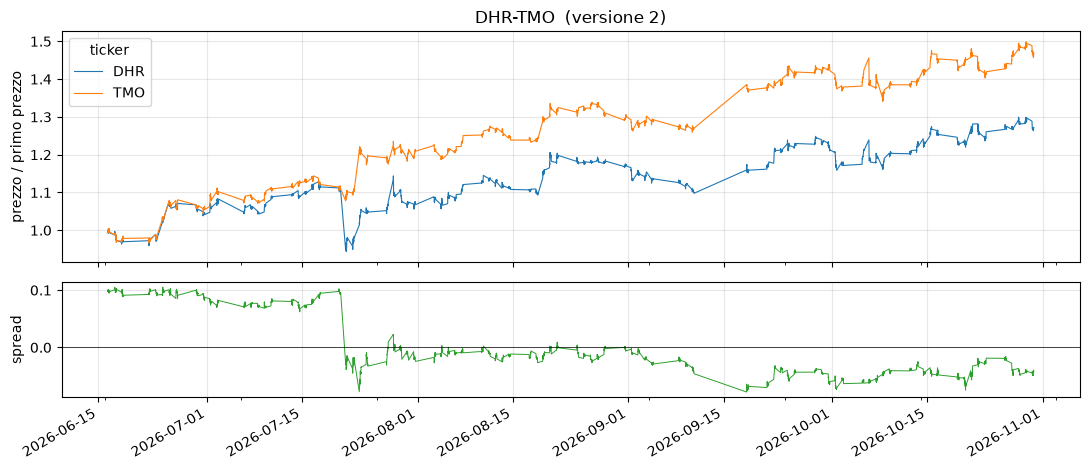

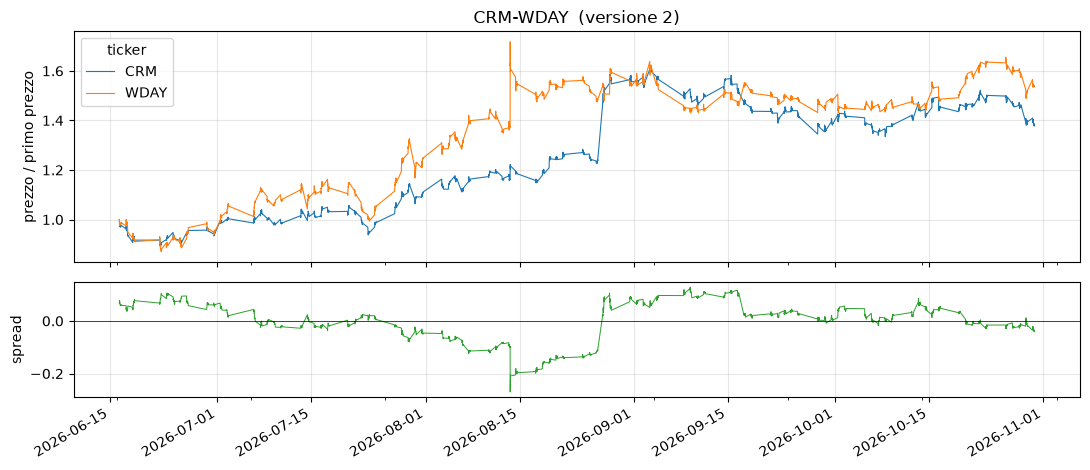

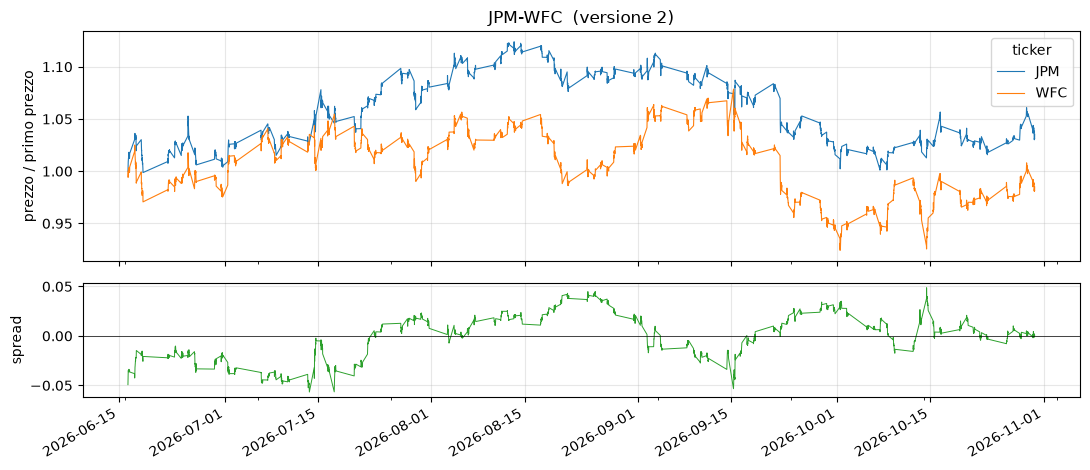

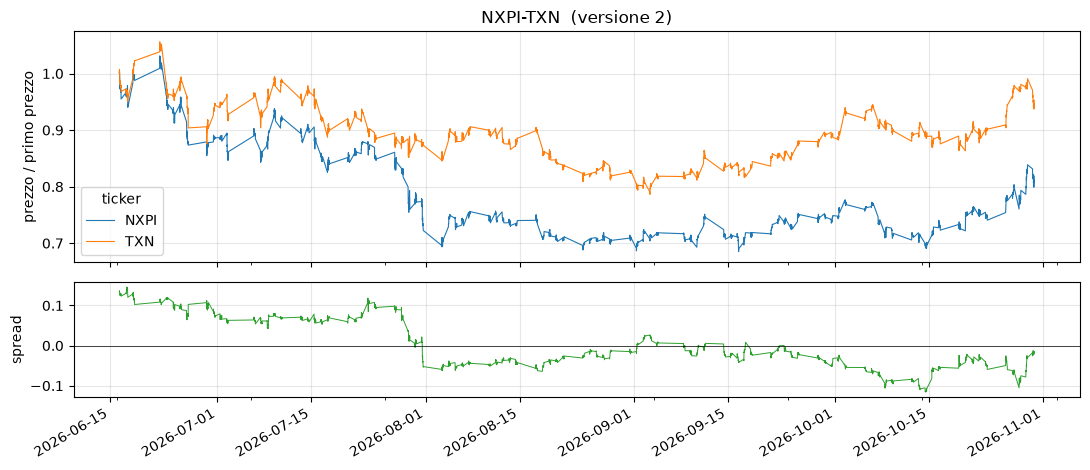

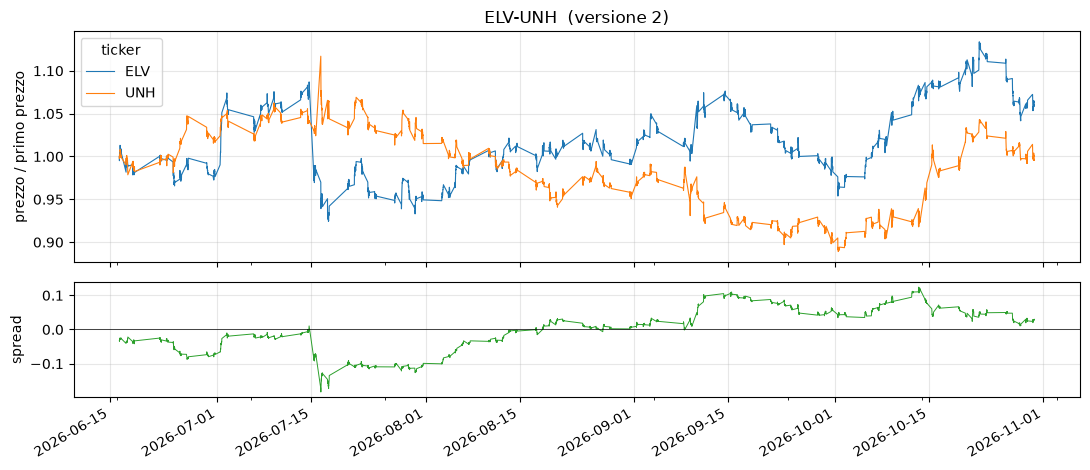

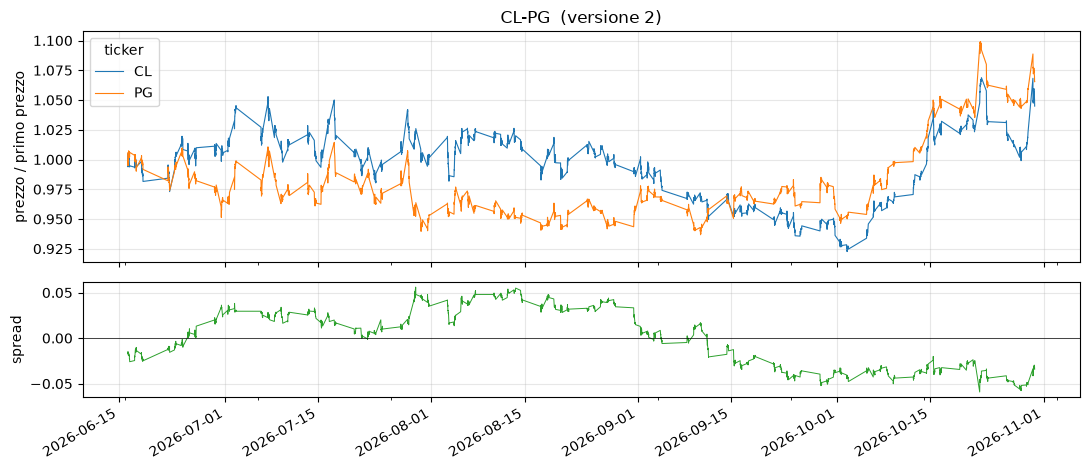

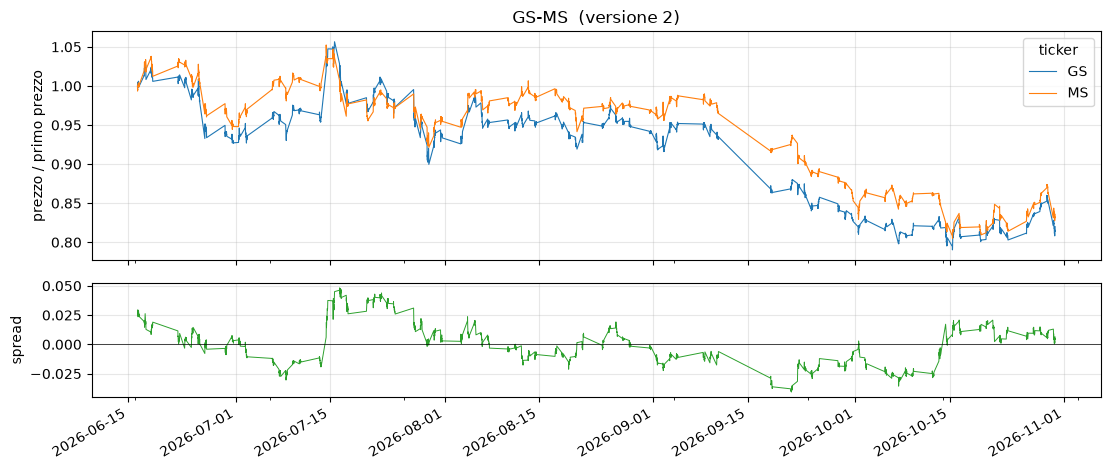

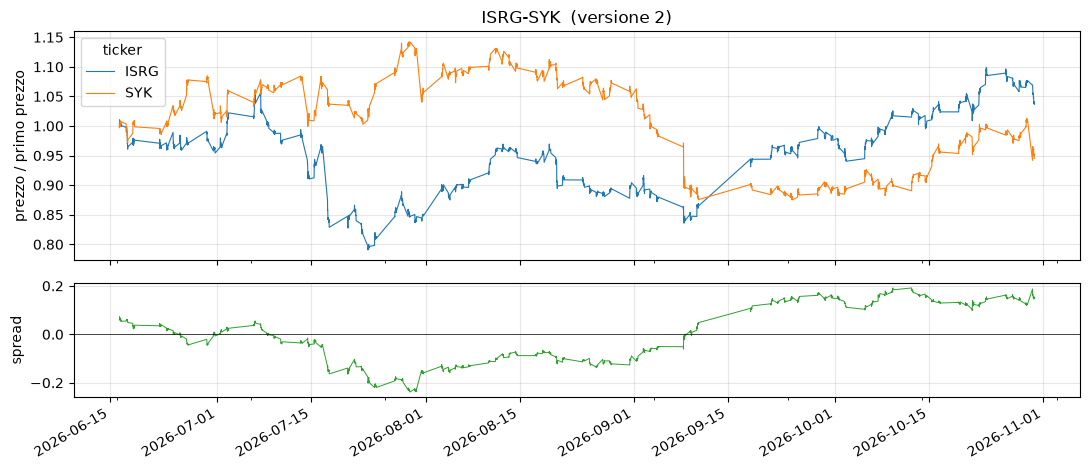

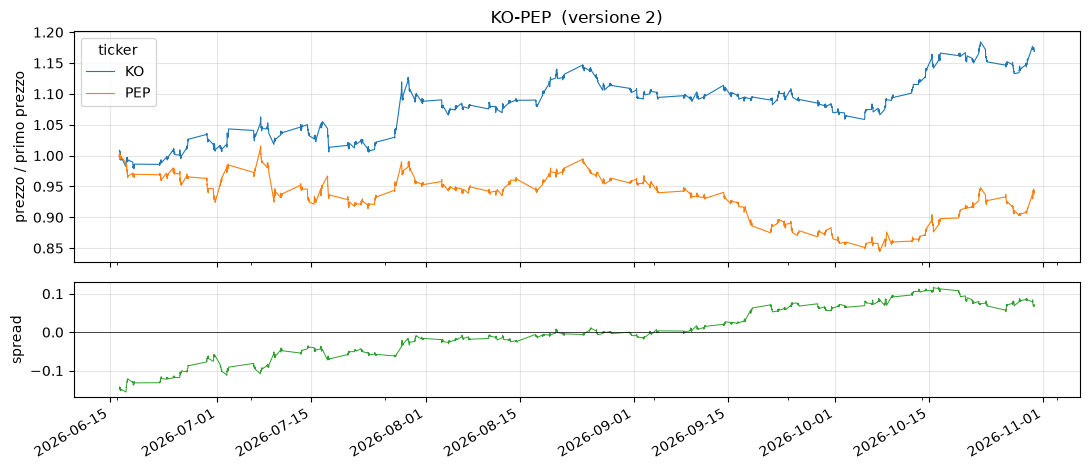

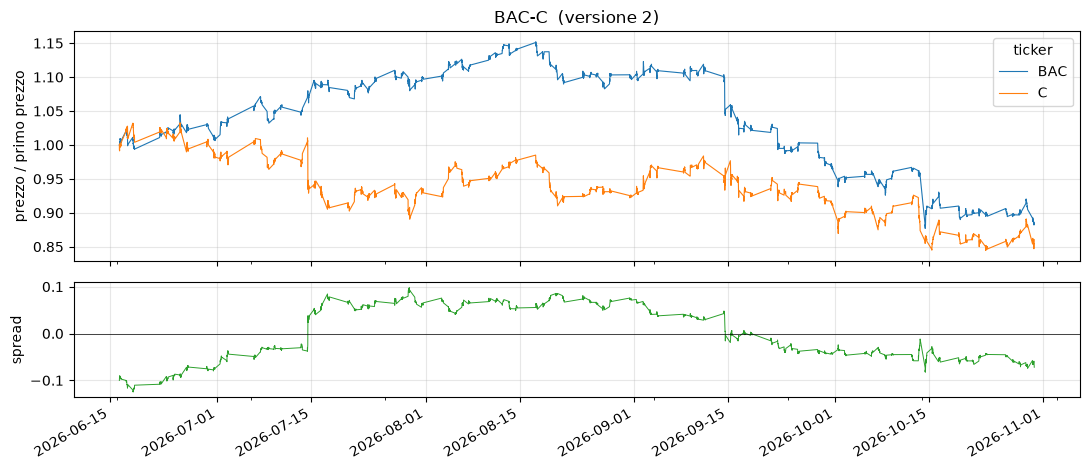

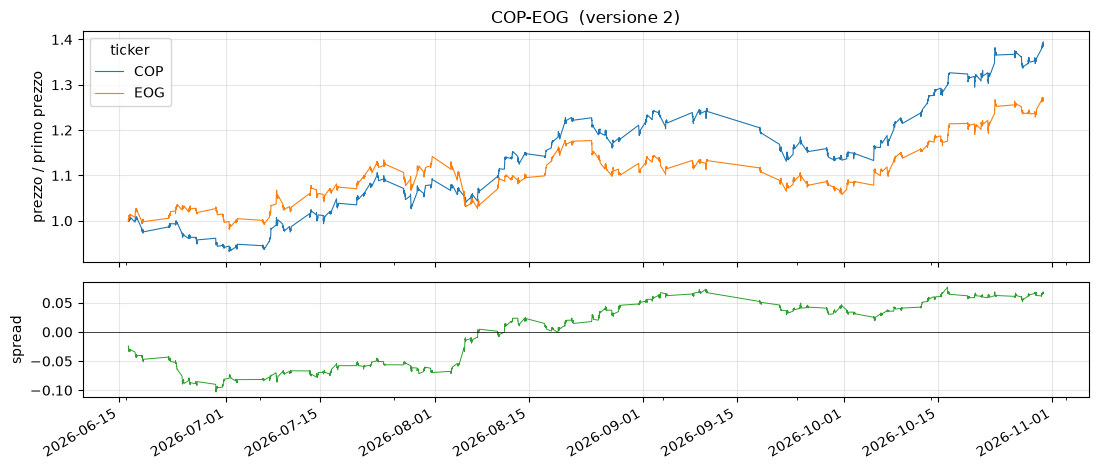

In [10]:
for p, long in clean.items():
    wide = resample_bars(long, 15).pivot(index="ts", columns="ticker", values="close")
    a, b = pairs.loc[pairs["pair"] == p, ["A", "B"]].iloc[0]
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 4.8), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
    (wide / wide.iloc[0]).rename(columns=lambda c: c.split()[0]).plot(ax=ax1, lw=0.8)
    ax1.set_title(f"{p}  ({pairs.loc[pairs['pair'] == p, 'origine'].iloc[0]})"); ax1.set_ylabel("prezzo / primo prezzo"); ax1.grid(alpha=0.3)
    spread = np.log(wide[a] / wide[b]); (spread - spread.mean()).plot(ax=ax2, lw=0.7, color="C2")
    ax2.axhline(0, color="k", lw=0.5); ax2.set_ylabel("spread"); ax2.set_xlabel(""); ax2.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

## 9. Risultati (testo per il report)

La cella seguente genera il testo dai risultati del notebook: se si rilancia con altri dati, i numeri si aggiornano da soli. Riporta cosa è stato controllato e cosa è stato fatto ai dati di ogni coppia.


In [11]:
from IPython.display import Markdown, display

n_days_all = len(day_bars)
bad_split = len(suspect_px)
big_gaps = suspect_gap[["ticker", "date", "gap"]]
q = quality.copy()
worst = pd.concat([q[["titolo_A", "filled_%_A"]].set_axis(["titolo", "filled"], axis=1), q[["titolo_B", "filled_%_B"]].set_axis(["titolo", "filled"], axis=1)]).sort_values("filled", ascending=False).head(5)
lost = q[q["minuti_iniziali_scartati"] > 0]["minuti_iniziali_scartati"].sort_values(ascending=False)
lines = [
    "### Cosa abbiamo fatto",
    f"Abbiamo ripulito i dati a 1 minuto dei {len(tickers)} titoli delle {len(pairs)} coppie della versione 2 (stesso metodo della versione 1): seduta regolare 09:30-15:59 (390 barre al giorno), giorni in comune per ogni coppia, minuti senza scambi riempiti con l'ultimo prezzo **dello stesso giorno** (mai prezzi futuri, mai prezzi del giorno prima), minuti iniziali senza prezzo tolti a entrambi i titoli. Per ogni coppia sono salvate le frequenze {', '.join(str(m) for m in FREQUENCIES)} minuti in `data/processed/pairs_intraday_v2/`.",
    "",
    "### Perche",
    "I prezzi intraday sono il materiale del segnale e della simulazione: devono avere gli stessi orari per i due titoli e nessuna informazione futura (lookahead bias). Lo spread di una coppia non esiste in un giorno in cui manca uno dei due titoli, e un prezzo copiato attraverso la notte sarebbe falso.",
    "",
    "### Risultati",
    f"- **Periodo**: {raw['date'].min().date()} - {raw['date'].max().date()}, {n_days_all} giorni di borsa con almeno un titolo; giorni a orario ridotto: {len(half_days)}.",
    f"- **Split**: {len(suspect_gap)} gap notturni oltre il {SPLIT_GAP:.0%}" + (" (" + ", ".join(f"{r.ticker.split()[0]} {r.date.date()} {r.gap:+.1%}" for r in big_gaps.itertuples()) + ")" if len(big_gaps) else "") + f"; {bad_split} casi di chiusura intraday oltre il {CLOSE_VS_DAILY_TOL:.0%} dal giornaliero aggiustato. " + ("Nessuno split nei titoli." if bad_split == 0 else "Da controllare a mano prima di usare i prezzi."),
    f"- **Giorni per coppia**: da {int(q['giorni_tenuti'].min())} a {int(q['giorni_tenuti'].max())}; coppie con giorni scartati: " + (", ".join(f"{p} ({int(r)})" for p, r in q["giorni_scartati"][q["giorni_scartati"] > 0].items()) or "nessuna") + ".",
    "- **Minuti iniziali tolti** (tutto il periodo): " + (", ".join(f"{p} {int(v)}" for p, v in lost.items()) or "nessuno") + ".",
    "- **Barre riempite a 1 minuto**, titoli piu colpiti: " + ", ".join(f"{r.titolo} {r.filled:.0f}%" for r in worst.itertuples()) + ".",
    f"- **Salti sopra il {JUMP_1MIN:.0%} in un minuto dopo la pulizia**: {int(q[['salti_1min_A', 'salti_1min_B']].sum().sum())}.",
    "",
    "### Cosa significa",
    "- Le coppie con un titolo poco scambiato hanno molti minuti riempiti: li' lo spread a 1 minuto puo muoversi solo perche una gamba e ferma. E la decisione B del Programma (come trattare le barre riempite nel segnale), da prendere prima del Passaggio 4.",
    "- Le coppie con meno giorni hanno meno dati per addestramento e test.",
    "- Divisione train/test e frequenza di base restano da decidere (decisioni A e 1 del Programma).",
]
display(Markdown("\n".join(lines)))

### Cosa abbiamo fatto
Abbiamo ripulito i dati a 1 minuto dei 30 titoli delle 15 coppie della versione 2 (stesso metodo della versione 1): seduta regolare 09:30-15:59 (390 barre al giorno), giorni in comune per ogni coppia, minuti senza scambi riempiti con l'ultimo prezzo **dello stesso giorno** (mai prezzi futuri, mai prezzi del giorno prima), minuti iniziali senza prezzo tolti a entrambi i titoli. Per ogni coppia sono salvate le frequenze 1, 5, 15, 60 minuti in `data/processed/pairs_intraday_v2/`.

### Perche
I prezzi intraday sono il materiale del segnale e della simulazione: devono avere gli stessi orari per i due titoli e nessuna informazione futura (lookahead bias). Lo spread di una coppia non esiste in un giorno in cui manca uno dei due titoli, e un prezzo copiato attraverso la notte sarebbe falso.

### Risultati
- **Periodo**: 2026-06-16 - 2026-10-30, 96 giorni di borsa con almeno un titolo; giorni a orario ridotto: 0.
- **Split**: 2 gap notturni oltre il 15% (DHR 2026-07-21 -16.5%, PYPL 2026-07-15 +15.8%); 0 casi di chiusura intraday oltre il 5% dal giornaliero aggiustato. Nessuno split nei titoli.
- **Giorni per coppia**: da 91 a 96; coppie con giorni scartati: CSX-UNP (5), HD-LOW (5), DHR-TMO (5), GS-MS (5), ISRG-SYK (5), COP-EOG (5).
- **Minuti iniziali tolti** (tutto il periodo): BAC-C 124, JPM-WFC 109, PYPL-XYZ 74, GS-MS 59, CL-PG 56, ISRG-SYK 35, HD-LOW 24, DHR-TMO 11, KO-PEP 4, CRM-WDAY 3, ELV-UNH 1.
- **Barre riempite a 1 minuto**, titoli piu colpiti: UNP 41%, ELV 36%, LOW 32%, DHR 25%, EOG 24%.
- **Salti sopra il 5% in un minuto dopo la pulizia**: 3.

### Cosa significa
- Le coppie con un titolo poco scambiato hanno molti minuti riempiti: li' lo spread a 1 minuto puo muoversi solo perche una gamba e ferma. E la decisione B del Programma (come trattare le barre riempite nel segnale), da prendere prima del Passaggio 4.
- Le coppie con meno giorni hanno meno dati per addestramento e test.
- Divisione train/test e frequenza di base restano da decidere (decisioni A e 1 del Programma).

## 10. Salvataggio e riepilogo

Si salva un file Parquet per ogni coppia e frequenza in `data/processed/pairs_intraday_v2/` (cartella ignorata da git: chi nel gruppo ne ha bisogno rilancia il notebook), più la tabella di qualità in CSV. I file sono in formato lungo (un titolo per riga), come concordato per i passaggi successivi; la funzione `load_pair` qui sotto li restituisce già in forma larga (una colonna per titolo), comoda per calcolare lo spread.

In [12]:
OUT_DIR.mkdir(parents=True, exist_ok=True)
con = duckdb.connect()
n_files = 0
for p, long in clean.items():
    for m in FREQUENCIES:
        df = resample_bars(long, m) if m != 1 else long
        con.register("t", df)
        con.execute(f"COPY t TO '{(OUT_DIR / f'{p}_{m}min.parquet').as_posix()}' (FORMAT PARQUET, COMPRESSION ZSTD)")
        con.unregister("t")
        n_files += 1
quality.to_csv(OUT_DIR / "quality_summary.csv")
print(n_files, "file salvati in", f"data/processed/{OUT_DIR.name}")

60 file salvati in data/processed/pairs_intraday_v2


In [13]:
def load_pair(pair, minutes=1, field="close"):
    # Legge un file pulito e lo restituisce in forma larga: una riga per orario, una colonna per titolo.
    df = duckdb.sql(f"SELECT * FROM '{(OUT_DIR / f'{pair}_{minutes}min.parquet').as_posix()}'").df()
    return df.pivot(index="ts", columns="ticker", values=field)

load_pair("KO-PEP", 15).head()

ticker,KO UN Equity,PEP UW Equity
ts,,
2026-06-16 09:30:00,80.49,146.45
2026-06-16 09:45:00,80.31,146.02
2026-06-16 10:00:00,80.94,146.36
2026-06-16 10:15:00,81.20,147.20
2026-06-16 10:30:00,80.68,146.31


**Cosa è stato fatto e cosa resta aperto**
- I prezzi intraday dei 30 titoli delle coppie della versione 2 sono controllati (split, giorni mancanti, giorni a orario ridotto), allineati per coppia e riempiti in avanti solo dentro la giornata, senza usare prezzi futuri.
- Per ogni coppia ci sono i file a 1, 5, 15 e 60 minuti e la tabella di qualità, in `data/processed/pairs_intraday_v2/` (la versione 1 resta in `data/processed/pairs_intraday/`).
- **Limiti da dichiarare nel report:**
  1. il volume intraday è solo una parte del volume totale (in quota diversa per borsa): va usato come indicatore relativo, non assoluto;
  2. la quota di barre riempite è alta per i titoli poco scambiati (spread che cambia meno spesso di quanto sembri);
  3. giorni scartati per le coppie con dati mancanti: meno giorni a disposizione per addestramento e test;
  4. prezzi non aggiustati per dividendi: in pochi mesi i dividendi sono pochi e piccoli, ma restano un'approssimazione;
  5. circa 3 mesi di dati: un solo tipo di mercato.
- **Prossimo passo** (Passaggio 4): spread e segnale su questi file. La divisione tra addestramento e test (decisione 3) va ancora fissata.